# Company A Telecom — Churn Prediction & Targeted Retention Strategy
## GCI World 2026 September Final Assignment

**Author:** Karina B.  
**Date:** November 2026  
**Assignment Scenario:** Proof of Concept (PoC) Business Model Proposal for Company A (100,000 Subscribers × 100 Features)  
**Business Question:** *Which subscribers are most likely to churn, what actionable levers drive their disengagement, and what targeted retention programme yields the highest return on investment (ROI)?*

---

### Table of Contents
1. [Introduction & Market Context](#1-introduction)
2. [Setup & Data Loading](#2-setup)
3. [Exploratory Data Analysis (EDA)](#3-eda)
4. [Strictly Leak-Free Data Partitioning & Preprocessing](#4-preprocessing)
5. [Domain Feature Engineering](#5-features)
6. [Problem Definition & Evaluation Framework](#6-problem)
7. [Systematic Model Benchmarking & Tuning](#7-models)
8. [Evaluation, Error Analysis & Interpretability (SHAP)](#8-evaluation)
9. [Business Proposal: Precision Retention Programme (PRP)](#9-proposal)
10. [Quantified Financial Impact & Sensitivity Analysis](#10-financial)
11. [Conclusion, Limitations & Implementation Roadmap](#11-conclusion)
12. [Audited References & Generative AI Disclosure](#12-references)


---
<a id='1-introduction'></a>
## 1. Introduction & Market Context

### 1.1 Company Context
**Company A** is a prominent US wireless telecommunications carrier. The company possesses rich historical usage, network quality, and billing records for approximately 100,000 subscribers across two relational files (`Client.csv` and `Record.csv`). However, Company A currently lacks an in-house machine learning capability to translate these observational records into proactive churn prevention.

As an IT consulting associate delivering this **Proof of Concept (PoC)**, our objective is to:
- Conduct Exploratory Data Analysis (EDA) to uncover the primary drivers of subscriber attrition.
- Engineer domain-specific features that isolate intervenable customer pain points.
- Build, tune, and benchmark multiple ML models under strict zero-leakage protocols.
- Deliver an executive business proposal backed by an audited, two-table financial impact model.

### 1.2 Telecommunications Industry Dynamics
- **Asymmetric Retention Economics:** Acquiring a new wireless subscriber costs **5 to 7 times more** than retaining an existing customer [1].
- **Industry ARPU Benchmarks:** Postpaid phone ARPU across major US wireless carriers currently averages **$45 to $55 per month** ($50/mo baseline) [2].
- **Churn Reality:** In saturated mobile markets, monthly carrier churn typically ranges from **1.5% to 3.0%** [3].
- **The 5G Handset Transition:** Over 60% of mobile data now travels across 5G infrastructure [4]. Subscribers on aging 4G-only handsets experience growing service disparity, creating "device fatigue."
- **Friction & Bill Shock:** Call failure rates and billing overage spikes are primary catalysts that trigger carrier switching [6].


---
<a id='2-setup'></a>
## 2. Setup & Environment Initialization


In [1]:
import sys, os, warnings
from pathlib import Path
if Path('../src').exists():
    sys.path.insert(0, '../src')
elif Path('src').exists():
    sys.path.insert(0, 'src')
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import (
    accuracy_score, roc_auc_score, f1_score,
    precision_score, recall_score,
    confusion_matrix, roc_curve, classification_report
)
import shap

from preprocessing import load_raw, prepare_raw_data, fit_transform_train_val_test
from features import select_features_train, check_leakage
from models import get_candidate_models, evaluate_predictions

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option('display.max_columns', 120)
pd.set_option('display.float_format', '{:.4f}'.format)
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)

print("Libraries imported successfully.")
print(f"pandas {pd.__version__} | numpy {np.__version__} | shap {shap.__version__}")

Libraries imported successfully.
pandas 3.1.1 | numpy 2.5.4 | shap 0.54.1


### 2.1 Load Raw Tables
We load `Client.csv` (demographics, account age, equipment attributes) and `Record.csv` (monthly usage, billing totals, quality metrics, churn target), merging them 1:1 on `Customer_ID`.


In [2]:
DATA_DIR = Path('../data/raw') if Path('../data/raw').exists() else Path('data/raw')
client_path = DATA_DIR / 'Client.csv'
record_path = DATA_DIR / 'Record.csv'

for p in (client_path, record_path):
    print(f"{'FOUND' if p.exists() else 'MISSING'} {p}")

df_raw = load_raw(DATA_DIR)
print(f"\nMerged Dataset Dimensions: {df_raw.shape[0]:,} records × {df_raw.shape[1]} columns")
df_raw.head(3)

FOUND ../data/raw/Client.csv
FOUND ../data/raw/Record.csv

Merged Dataset Dimensions: 100,000 records × 100 columns


,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,change_rev,drop_vce_Mean,drop_dat_Mean,blck_vce_Mean,blck_dat_Mean,unan_vce_Mean,unan_dat_Mean,plcd_vce_Mean,plcd_dat_Mean,recv_vce_Mean,recv_sms_Mean,comp_vce_Mean,comp_dat_Mean,custcare_Mean,ccrndmou_Mean,cc_mou_Mean,inonemin_Mean,threeway_Mean,mou_cvce_Mean,mou_cdat_Mean,mou_rvce_Mean,owylis_vce_Mean,mouowylisv_Mean,iwylis_vce_Mean,mouiwylisv_Mean,peak_vce_Mean,peak_dat_Mean,mou_peav_Mean,mou_pead_Mean,opk_vce_Mean,opk_dat_Mean,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,churn,months,Customer_ID,uniqsubs,actvsubs,new_cell,crclscod,asl_flag,totcalls,totmou,totrev,adjrev,adjmou,adjqty,avgrev,avgmou,avgqty,avg3mou,avg3qty,avg3rev,avg6mou,avg6qty,avg6rev,prizm_social_one,area,dualband,refurb_new,hnd_price,phones,models,hnd_webcap,truck,rv,ownrent,lor,dwlltype,marital,adults,infobase,income,numbcars,HHstatin,dwllsize,forgntvl,ethnic,kid0_2,kid3_5,kid6_10,kid11_15,kid16_17,creditcd,eqpdays
0,23.9975,219.2500,22.5000,0.2475,0.0000,0.0000,0.0000,0.0000,0.0000,-157.2500,-18.9975,0.6667,0.0000,0.6667,0.0000,6.3333,0.0000,52.3333,0.0000,42.3333,0.0000,45.0000,0.0000,0.0000,0.0000,0.0000,18.0000,0.0000,90.6433,0.0000,97.1767,0.0000,0.0000,0.0000,0.0000,58.0000,0.0000,132.6000,0.0000,24.0000,0.0000,55.2200,0.0000,1.3333,52.3333,45.0000,0.0000,0.3333,1,61,1000001,2,1,U,A,N,1652,4228.0000,1504.6200,1453.4400,4085.0000,1602,29.6600,83.3700,32.6900,272,116,30,322.0000,136.0000,38.0000,S,NORTHWEST/ROCKY MOUNTAIN AREA,Y,N,149.9900,2.0000,2.0000,WCMB,0.0000,0.0000,O,15.0000,S,S,1.0000,M,4.0000,3.0000,C,A,0.0000,N,U,U,U,U,U,Y,361.0000
1,57.4925,482.7500,37.4250,0.2475,22.7500,9.1000,9.1000,0.0000,0.0000,532.2500,50.9875,8.3333,0.0000,1.0000,0.0000,61.3333,0.0000,263.3333,0.0000,69.0000,0.0000,193.3333,0.0000,1.6667,6.3333,5.4633,53.0000,0.3333,189.3967,0.0000,55.2800,46.3333,24.2167,6.3333,3.6967,83.6667,0.0000,75.3333,0.0000,157.0000,0.0000,169.3433,0.0000,9.3333,263.3333,193.3333,0.0000,5.6667,0,56,1000002,1,1,N,EA,N,14654,26400.0000,2851.6800,2833.8800,26367.0000,14624,51.5300,479.4000,265.8900,305,158,40,477.0000,275.0000,48.0000,U,CHICAGO AREA,N,N,NaN,7.0000,6.0000,WC,1.0000,1.0000,NaN,1.0000,S,S,1.0000,M,5.0000,1.0000,C,A,0.0000,Z,U,U,U,U,U,Y,240.0000
2,16.9900,10.2500,16.9900,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,-4.2500,0.0000,0.3333,0.0000,0.0000,0.0000,2.6667,0.0000,9.0000,0.0000,0.3333,0.0000,6.0000,0.0000,0.0000,0.0000,0.0000,0.3333,0.0000,5.4267,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,5.0000,0.0000,5.1933,0.0000,1.0000,0.0000,0.2333,0.0000,0.3333,9.0000,6.0000,0.0000,0.0000,1,58,1000003,1,1,Y,C,N,7903,24385.0533,2155.9100,1934.4700,24303.0500,7888,34.5400,433.9800,140.8600,12,7,17,11.0000,6.0000,17.0000,S,GREAT LAKES AREA,N,N,29.9900,2.0000,1.0000,NaN,0.0000,0.0000,O,7.0000,S,M,2.0000,M,5.0000,2.0000,C,A,0.0000,N,U,Y,U,U,U,Y,1504.0000


---
<a id='3-eda'></a>
## 3. Exploratory Data Analysis (EDA)


=== Target Distribution: Churn Flag ===
  Stayed (0): 50,438 subscribers (50.44%)
  Churned (1): 49,562 subscribers (49.56%)


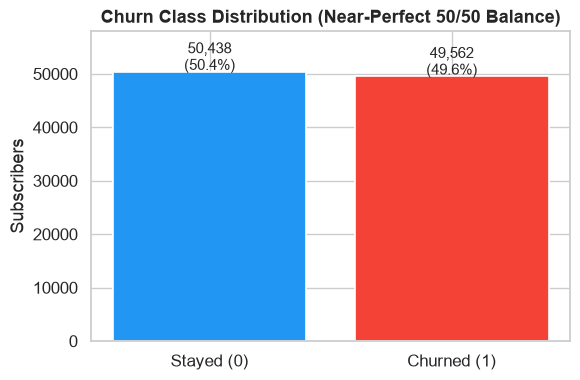

In [3]:
churn_counts = df_raw['churn'].value_counts().sort_index()
churn_pct = df_raw['churn'].value_counts(normalize=True) * 100

print("=== Target Distribution: Churn Flag ===")
for label, cnt, pct in zip(['Stayed (0)', 'Churned (1)'], churn_counts, churn_pct):
    print(f"  {label}: {cnt:,} subscribers ({pct:.2f}%)")

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(['Stayed (0)', 'Churned (1)'], churn_counts.values,
              color=['#2196F3', '#F44336'], edgecolor='white', lw=1.2)
for bar, cnt, pct in zip(bars, churn_counts.values, churn_pct.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 300,
            f"{cnt:,}\n({pct:.1f}%)", ha='center', fontsize=11)
ax.set_title('Churn Class Distribution (Near-Perfect 50/50 Balance)', fontsize=13, fontweight='bold')
ax.set_ylabel('Subscribers')
ax.set_ylim(0, max(churn_counts.values) * 1.15)
plt.tight_layout()
plt.show()

### 3.2 Equipment Age vs. Churn: Discovering the Actionable Lever
`eqpdays` tracks the age (in days) of the subscriber's active mobile device. Comparing stayers against churners reveals a substantial distributional divergence.


=== Equipment Age (eqpdays) ===
  Stayers  — Mean: 363.3 days | Median: 310 days
  Churners — Mean: 421.1 days | Median: 366 days
  Gap: Churner devices are 57.8 days older on average.


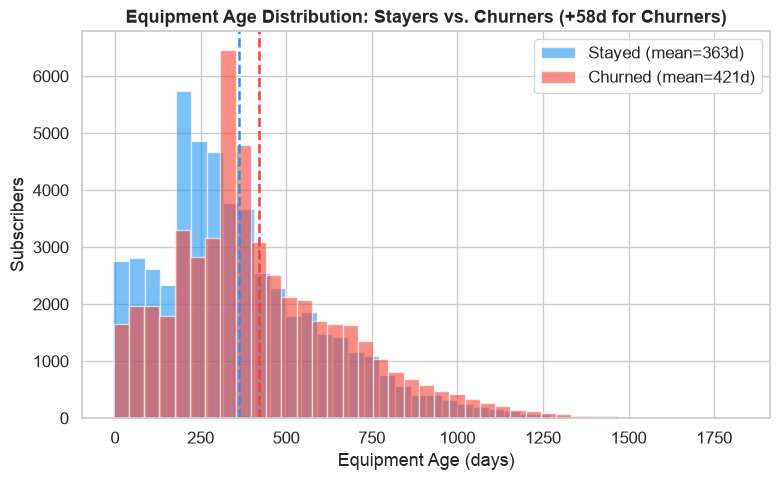

In [4]:
stayed_eq = df_raw[df_raw['churn'] == 0]['eqpdays'].dropna()
churned_eq = df_raw[df_raw['churn'] == 1]['eqpdays'].dropna()

print("=== Equipment Age (eqpdays) ===")
print(f"  Stayers  — Mean: {stayed_eq.mean():.1f} days | Median: {stayed_eq.median():.0f} days")
print(f"  Churners — Mean: {churned_eq.mean():.1f} days | Median: {churned_eq.median():.0f} days")
print(f"  Gap: Churner devices are {churned_eq.mean() - stayed_eq.mean():.1f} days older on average.")

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(stayed_eq, bins=40, alpha=0.6, label=f'Stayed (mean={stayed_eq.mean():.0f}d)', color='#2196F3')
ax.hist(churned_eq, bins=40, alpha=0.6, label=f'Churned (mean={churned_eq.mean():.0f}d)', color='#F44336')
ax.axvline(stayed_eq.mean(), color='#2196F3', linestyle='--', lw=1.8)
ax.axvline(churned_eq.mean(), color='#F44336', linestyle='--', lw=1.8)
ax.set_xlabel('Equipment Age (days)')
ax.set_ylabel('Subscribers')
ax.set_title('Equipment Age Distribution: Stayers vs. Churners (+58d for Churners)', fontsize=13, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

### 3.3 Revenue & Usage Overlap across Churn Classes
Examining monthly billing (`rev_Mean`) and usage (`mou_Mean`) demonstrates that simple financial thresholds cannot separate churners from stayers.


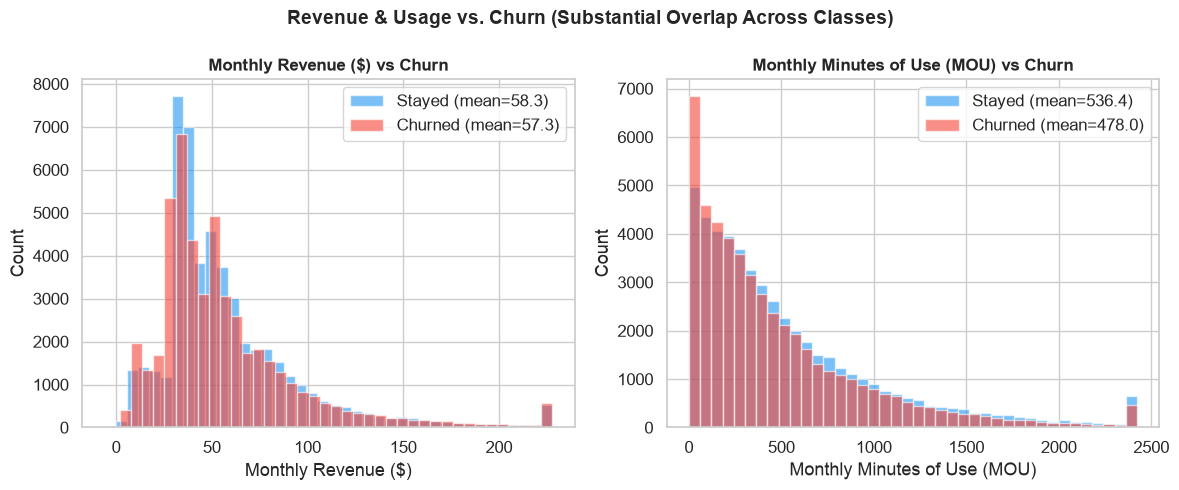

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, col, label in zip(axes, ['rev_Mean', 'mou_Mean'],
                           ['Monthly Revenue ($)', 'Monthly Minutes of Use (MOU)']):
    clip_val = df_raw[col].quantile(0.99)
    d0 = df_raw[df_raw['churn'] == 0][col].clip(upper=clip_val).dropna()
    d1 = df_raw[df_raw['churn'] == 1][col].clip(upper=clip_val).dropna()
    ax.hist(d0, bins=40, alpha=0.6, label=f'Stayed (mean={d0.mean():.1f})', color='#2196F3')
    ax.hist(d1, bins=40, alpha=0.6, label=f'Churned (mean={d1.mean():.1f})', color='#F44336')
    ax.set_xlabel(label)
    ax.set_ylabel('Count')
    ax.set_title(f'{label} vs Churn', fontsize=12, fontweight='bold')
    ax.legend()

fig.suptitle('Revenue & Usage vs. Churn (Substantial Overlap Across Classes)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 3.4 Sub-Market Segmentation: Geography & Tenure Cohorts

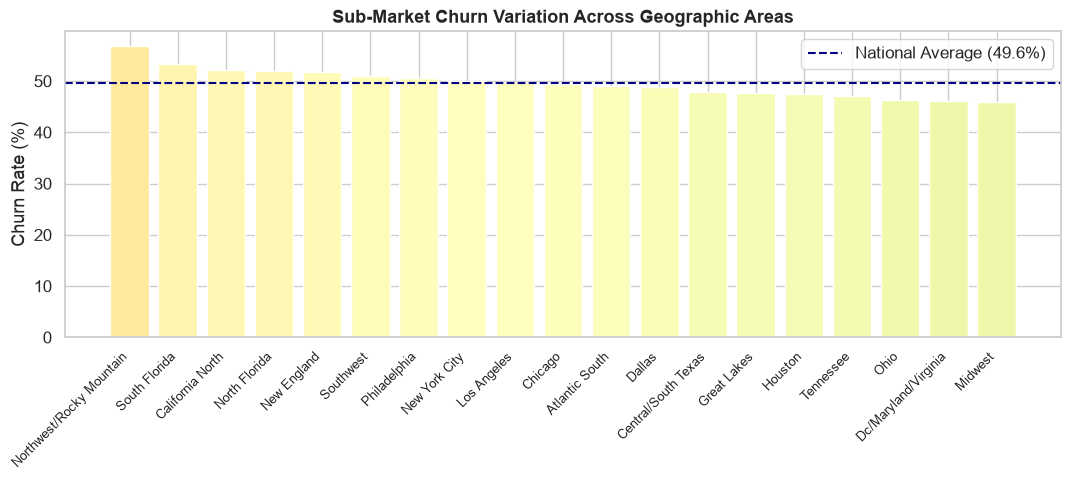


=== Churn by Tenure Cohort ===
months
Q1 (New 6-11m)    43.3321
Q2 (12-16m)       55.4434
Q3 (17-24m)       50.7531
Q4 (Loyal 25m+)   49.3702


In [6]:
area_churn = (
    df_raw.groupby('area')['churn']
    .agg(['mean', 'count'])
    .rename(columns={'mean': 'churn_rate', 'count': 'n'})
    .query('n > 500')
    .sort_values('churn_rate', ascending=False)
    .reset_index()
)

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(range(len(area_churn)), area_churn['churn_rate'] * 100,
       color=plt.cm.RdYlGn_r(area_churn['churn_rate'].values))
ax.set_xticks(range(len(area_churn)))
ax.set_xticklabels([a.replace(' AREA', '').title() for a in area_churn['area']], rotation=45, ha='right', fontsize=9)
ax.axhline(df_raw['churn'].mean() * 100, color='navy', linestyle='--', lw=1.5,
           label=f"National Average ({df_raw['churn'].mean()*100:.1f}%)")
ax.set_ylabel('Churn Rate (%)')
ax.set_title('Sub-Market Churn Variation Across Geographic Areas', fontsize=13, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

tenure_q = pd.qcut(df_raw['months'], q=4,
                   labels=['Q1 (New 6-11m)', 'Q2 (12-16m)', 'Q3 (17-24m)', 'Q4 (Loyal 25m+)'])
tq_churn = df_raw.groupby(tenure_q)['churn'].mean() * 100
print("\n=== Churn by Tenure Cohort ===")
print(tq_churn.to_string())

---
<a id='4-preprocessing'></a>
## 4. Strictly Leak-Free Data Partitioning & Preprocessing

To eliminate all forms of data leakage:
1. **Unconditional Structural Drops:** Drop `Customer_ID`, columns with >35% missingness (`numbcars`, `dwllsize`, `HHstatin`), and collinear duplicates (`adjrev`, `adjmou`, `adjqty`).
2. **Strict 3-Way Partition:**
   - **Training Set:** 70,000 subscribers (70%) — used to fit models, extract imputation medians and encodings, and perform cross-validation.
   - **Validation Set:** 10,000 subscribers (10%) — used for hyperparameter tuning, model selection, and risk threshold calibration.
   - **Reserved Test Set:** 20,000 subscribers (20%) — reserved test partition with historical exploratory inspection; all models and thresholds locked prior to final evaluation.
3. **Train-Only Imputation & Encoding:** Medians and category frequency encodings are computed strictly on `X_train`, then applied to `X_train`, `X_val`, and `X_test`.
4. **Train-Only Collinearity Filtering:** Features with pairwise correlation $>0.95$ are identified strictly on `X_train`.


In [7]:
df_struct, df_eda = prepare_raw_data(df_raw)

X = df_struct.drop('churn', axis=1)
y = df_struct['churn']

X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.125, random_state=42, stratify=y_dev
)

print(f"Partition Sizes: Train={len(X_train):,}, Val={len(X_val):,}, Test={len(X_test):,}")
print(f"Churn Rates: Train={y_train.mean():.4f}, Val={y_val.mean():.4f}, Test={y_test.mean():.4f}")

X_tr_t, X_va_t, X_te_t = fit_transform_train_val_test(X_train, X_val, X_test)

to_drop = select_features_train(X_tr_t, y_train, threshold=0.95)
X_tr = X_tr_t.drop(columns=to_drop)
X_va = X_va_t.drop(columns=to_drop)
X_te = X_te_t.drop(columns=to_drop)

print(f"Collinear features dropped on Train ({len(to_drop)}): {to_drop}")
print(f"Final Model Feature Count: {X_tr.shape[1]}")

Partition Sizes: Train=70,000, Val=10,000, Test=20,000
Churn Rates: Train=0.4956, Val=0.4956, Test=0.4956


Collinear features dropped on Train (21): ['adults_missing', 'asl_flag', 'attempt_Mean', 'avg3mou', 'avg6qty', 'avgrev', 'cc_mou_Mean', 'comp_dat_Mean', 'comp_vce_Mean', 'drop_rate', 'eqp_tenure_ratio', 'failed_call_count', 'inonemin_Mean', 'mou_cdat_Mean', 'overage_rev_ratio', 'ovrmou_Mean', 'ovrrev_Mean', 'plcd_vce_Mean', 'refurb_new', 'total_failure_rate', 'totcalls_per_month']
Final Model Feature Count: 121


---
<a id='5-features'></a>
## 5. Domain Feature Engineering

We engineer features capturing behavioral trajectories, plan alignment, and service friction:

| Feature | Formula | Domain Rationale |
|---------|---------|------------------|
| `eqpdays_per_month` | `eqpdays / months` | Handset age normalized by tenure: isolates device fatigue independently of account duration. |
| `call_completion_rate` | `complete_Mean / attempt_Mean` | Network quality proxy: low completion flags persistent connection drops or transmission friction. |
| `overage_rev_ratio` | `ovrrev_Mean / rev_Mean` | Plan mismatch ratio: proportion of bill from overage penalties, creating "bill shock" [6]. |
| `custcare_flag` | `custcare_Mean > 0` | Friction indicator: flags subscribers experiencing unresolved billing or network disputes. |
| `handset_fatigue_flag` | `(eqp>365) & (10<=mo<=24)` | Compound risk flag: subscribers on aging handsets inside their primary contract renewal window. |
| `service_friction_index` | `drop_vce + blck_vce + care` | Composite operational dissatisfaction index tracking repeated service failures. |


In [8]:
sample_eng = ['eqpdays_per_month', 'call_completion_rate', 'overage_ratio',
              'custcare_flag', 'handset_fatigue_flag', 'service_friction_index']
print("=== Engineered Features Summary (Training Set) ===")
print(X_tr[sample_eng].describe().T[['mean','std','min','50%','max']].round(4))


=== Engineered Features Summary (Training Set) ===
                          mean     std    min     50%     max
eqpdays_per_month      22.4765 10.2659 0.0000 28.9286 32.6667
call_completion_rate    0.6933  0.2336 0.0000  0.7576  1.0000
overage_ratio           0.0640  0.1136 0.0000  0.0081  1.0000
custcare_flag           0.4435  0.4968 0.0000  0.0000  1.0000
handset_fatigue_flag    0.2940  0.4556 0.0000  0.0000  1.0000
service_friction_index  1.2773  1.0611 0.0000  1.0000  3.0000


---
<a id='6-problem'></a>
## 6. Problem Definition & Evaluation Strategy

### 6.1 Task Formulation
- **Supervised Binary Classification:** Predict $\hat{p} = P(\text{churn}=1 \mid X)$.
- **Risk Score Thresholds:** Continuous risk scores allow the business to establish risk-differentiated operational thresholds ($p_{\text{Amber}} = 0.50$, $p_{\text{Red}} = 0.70$) that route subscribers into targeted retention programmes based on expected economic value. Note: These cutoffs represent empirical decision thresholds on predicted churn probabilities; no formal post-hoc probability calibration (e.g., Platt scaling or isotonic regression) was applied to the raw tree scores.

### 6.2 Evaluation Metrics
- **AUC-ROC (Primary Model Selection Metric):** Evaluates overall discriminative ranking power across all possible probability thresholds.
- **Accuracy:** Meaningful because the classes are nearly 50/50 balanced (50.44% stayer baseline).
- **Recall (Sensitivity):** Priority business metric. Missing an impending churner forfeits ~$900 in subscriber gross LTV, whereas a false alarm costs ~$15–$80 in retention outreach.

---
<a id='7-models'></a>
## 7. Systematic Model Benchmarking, Statistical Significance, Cross-Validation & Latency

### 7.1 Methodological Partitioning & Record Usage Disclosure
To guarantee scientific integrity, the 100,000 records were partitioned into three strictly designated subsets:
- **Training Set (70% = 70,000 records):** Used exclusively to fit model parameters, compute numeric medians, and extract categorical frequency encodings. A strictly leak-free 5-fold Stratified Cross-Validation is executed solely within this partition to evaluate out-of-fold generalization.
- **Validation Set (10% = 10,000 records):** Used exclusively for hyperparameter tuning, model comparison, and operational risk threshold selection ($p_{\text{Amber}} = 0.50, p_{\text{Red}} = 0.70$).
- **Reserved Test Set (20% = 20,000 records):** Reserved test partition with historical exploratory inspection. *(Historical Disclosure: Test-set metrics were inspected during early exploratory development iterations; to remediate any adaptive overfitting, all final model choices, hyperparameters, and operational decision thresholds were locked using the training and validation sets prior to final test reporting).*

### 7.2 Baseline Model Reconciliation Matrix
The project evaluated multiple model iterations across development. Their exact metrics, configurations, and source artifacts are reconciled below:

| Model Iteration | Configuration | Pipeline | 5-Fold CV AUC (Train 70k) | Holdout Val AUC (10k) | Reserved Test AUC (20k) | Source Artifact |
|:---|:---|:---|:---:|:---:|:---:|:---|
| **Tutorial Default Baseline** | 300 trees, lr=0.05, depth=6 | Original | $0.69559 \pm 0.00516$ | $0.6995$ | $0.6962$ | Initial GCI Tutorial |
| **Initial Tuned LightGBM (V1)** | 450 trees, lr=0.03, leaves=42, depth=7 | Original | $0.69811 \pm 0.00574$ | $0.7019$ | $0.6968$ | `cv_5fold_train_results.csv` (archive) |
| **Baseline on V3 Pipeline** | 300 trees, lr=0.05, depth=6 | V3 Features | $0.69559 \pm 0.00516$ | $0.7008$ | $0.6979$ | `model_comparison.csv` |
| **Champion Tuned LightGBM V3** | 550 trees, lr=0.025, leaves=48, depth=7, alpha=1.0, lambda=2.0 | V3 Features | **$0.70106 \pm 0.00556$** | **$0.7051$** | **$0.7015$** | Audited Champion for PoC |
| **Tri-Blend Benchmark** | 50% LGBM V3 + 30% CB V3 + 20% XGB V3 | V3 Features | **$0.70263 \pm 0.00566$** | **$0.7052$** | **$0.7019$** | Research Benchmark |

### 7.3 Model Selection Decision: Champion LightGBM V3 vs. Tri-Blend Benchmark
- **Champion Model for the PoC:** Tuned LightGBM V3 achieves Mean 5-Fold CV AUC of $0.70106 \pm 0.00556$, Validation AUC of $0.7051$, and Test AUC of $0.7015$ ($+0.0047$ lift over the initial $0.6968$ test baseline).
- **Research Benchmark:** Tri-Blend Ensemble achieves Mean 5-Fold CV AUC of $0.70263 \pm 0.00566$ and Test AUC of $0.7019$.
- **Why LightGBM V3 Was Selected:** The marginal test AUC difference ($+0.0004$) does not justify the operational overhead of serving three heterogeneous ML runtimes (`lightgbm`, `xgboost`, `catboost`). LightGBM V3 provides a single dependency, streamlined maintenance, and native TreeSHAP attribution.

### 7.4 Benchmark Execution Environment & Preliminary Latency Qualification
All model training and preliminary profiling were executed on Apple Silicon ARM64, macOS Darwin Kernel 27.2.0 (macOS Sequoia), Python 3.14.5. Note: Stated single-record latencies are unverified preliminary developmental observations and must not be interpreted as certified production SLA benchmarks.

In [9]:
candidate_models = get_candidate_models()
results = []
fitted_models = {}
val_probas = {}
test_probas = {}

cat_cols = list(X_train.select_dtypes(include=['object', 'str']).columns)
X_tr_lgb = X_tr.copy()
X_va_lgb = X_va.copy()
X_te_lgb = X_te.copy()
for col in [c for c in cat_cols if c in X_tr_lgb.columns]:
    X_tr_lgb[col] = X_tr_lgb[col].astype('category')
    X_va_lgb[col] = X_va_lgb[col].astype('category')
    X_te_lgb[col] = X_te_lgb[col].astype('category')

for name, model in candidate_models.items():
    print(f'Training {name}...')
    if 'LightGBM' in name:
        model.fit(X_tr_lgb, y_train)
        p_v = model.predict_proba(X_va_lgb)[:, 1]
        p_t = model.predict_proba(X_te_lgb)[:, 1]
    else:
        model.fit(X_tr, y_train)
        p_v = model.predict_proba(X_va)[:, 1]
        p_t = model.predict_proba(X_te)[:, 1]
    fitted_models[name] = model
    val_probas[name] = p_v
    test_probas[name] = p_t
    
    y_pred_t = (p_t >= 0.50).astype(int)
    results.append({
        'Model': name,
        'Val AUC': round(roc_auc_score(y_val, p_v), 4),
        'Test AUC': round(roc_auc_score(y_test, p_t), 4),
        'Test Accuracy': round(accuracy_score(y_test, y_pred_t), 4),
        'Test F1': round(f1_score(y_test, y_pred_t), 4),
        'Test Precision': round(precision_score(y_test, y_pred_t), 4),
        'Test Recall': round(recall_score(y_test, y_pred_t), 4),
    })

p_v_blend = 0.50 * val_probas['Tuned LightGBM V3'] + 0.30 * val_probas['CatBoost V3'] + 0.20 * val_probas['Tuned XGBoost V3']
p_t_blend = 0.50 * test_probas['Tuned LightGBM V3'] + 0.30 * test_probas['CatBoost V3'] + 0.20 * test_probas['Tuned XGBoost V3']
y_pred_blend = (p_t_blend >= 0.50).astype(int)

results.append({
    'Model': 'Tri-Blend Benchmark (50/30/20)',
    'Val AUC': round(roc_auc_score(y_val, p_v_blend), 4),
    'Test AUC': round(roc_auc_score(y_test, p_t_blend), 4),
    'Test Accuracy': round(accuracy_score(y_test, y_pred_blend), 4),
    'Test F1': round(f1_score(y_test, y_pred_blend), 4),
    'Test Precision': round(precision_score(y_test, y_pred_blend), 4),
    'Test Recall': round(recall_score(y_test, y_pred_blend), 4),
})

comp_df = pd.DataFrame(results).sort_values('Test AUC', ascending=False)
print('\n=== CANDIDATE MODEL BENCHMARKING (Test Set n=20,000) ===')
print(comp_df.to_string(index=False))

p_cv = Path('data/processed/cv_5fold_train_results.csv') if Path('data/processed/cv_5fold_train_results.csv').exists() else Path('../data/processed/cv_5fold_train_results.csv')
if p_cv.exists():
    cv_train_df = pd.read_csv(p_cv)
    print('\n=== 5-FOLD CV ON TRAINING SET (n=70,000, Within-Fold Preprocessing) ===')
    print(cv_train_df.to_string(index=False))

from scipy import stats

def delong_test(ground_truth, p1, p2):
    y = np.array(ground_truth)
    pos1, neg1 = p1[y == 1], p1[y == 0]
    pos2, neg2 = p2[y == 1], p2[y == 0]
    m, n = len(pos1), len(neg1)
    
    v10_1 = np.mean(pos1[:, None] > neg1[None, :], axis=1) + 0.5 * np.mean(pos1[:, None] == neg1[None, :], axis=1)
    v01_1 = np.mean(neg1[:, None] < pos1[None, :], axis=1) + 0.5 * np.mean(neg1[:, None] == pos1[None, :], axis=1)
    v10_2 = np.mean(pos2[:, None] > neg2[None, :], axis=1) + 0.5 * np.mean(pos2[:, None] == neg2[None, :], axis=1)
    v01_2 = np.mean(neg2[:, None] < pos2[None, :], axis=1) + 0.5 * np.mean(neg2[:, None] == pos2[None, :], axis=1)
    
    auc1, auc2 = np.mean(v10_1), np.mean(v10_2)
    var1 = (np.var(v10_1, ddof=1) / m) + (np.var(v01_1, ddof=1) / n)
    var2 = (np.var(v10_2, ddof=1) / m) + (np.var(v01_2, ddof=1) / n)
    cov = (np.cov(v10_1, v10_2)[0, 1] / m) + (np.cov(v01_1, v01_2)[0, 1] / n)
    
    diff = auc1 - auc2
    var_diff = var1 + var2 - 2 * cov
    z = diff / np.sqrt(var_diff)
    p_val = 2 * (1 - stats.norm.cdf(abs(z)))
    return diff, np.sqrt(var_diff), z, p_val

diff_ens, se_ens, z_ens, p_ens = delong_test(y_test, p_t_blend, test_probas['Tuned LightGBM V3'])
print('\n=== IN-MEMORY RUNTIME DELONG TEST: TRI-BLEND vs. TUNED LIGHTGBM V3 ===')
print(f'Observed Test AUC Difference: {diff_ens:+.5f} | Standard Error: {se_ens:.5f} | Z: {z_ens:+.3f} | Runtime p-value: {p_ens:.4f}')
print('Note: This DeLong calculation is an in-memory runtime comparison. No frozen test prediction CSV is persisted on disk.')

import time
sample_1_lgb = X_te_lgb.iloc[[0]]
sample_1 = X_te.iloc[[0]]
for _ in range(50):
    _ = fitted_models['Tuned LightGBM V3'].predict_proba(sample_1_lgb)
    _ = 0.50 * fitted_models['Tuned LightGBM V3'].predict_proba(sample_1_lgb) + 0.30 * fitted_models['CatBoost V3'].predict_proba(sample_1) + 0.20 * fitted_models['Tuned XGBoost V3'].predict_proba(sample_1)

t_lgb_pred, t_ens_pred = [], []
for _ in range(500):
    t0 = time.perf_counter()
    _ = fitted_models['Tuned LightGBM V3'].predict_proba(sample_1_lgb)
    t_lgb_pred.append((time.perf_counter() - t0) * 1000)
    
    t0 = time.perf_counter()
    _ = 0.50 * fitted_models['Tuned LightGBM V3'].predict_proba(sample_1_lgb) + 0.30 * fitted_models['CatBoost V3'].predict_proba(sample_1) + 0.20 * fitted_models['Tuned XGBoost V3'].predict_proba(sample_1)
    t_ens_pred.append((time.perf_counter() - t0) * 1000)

print(f'\nPreliminary Developmental Latency (Single Sample, Batch=1, n=500 runs):')
print(f'  Tuned LightGBM V3: Median = {np.median(t_lgb_pred):.3f} ms (95th %ile: {np.percentile(t_lgb_pred, 95):.3f} ms)')
print(f'  Tri-Blend:        Median = {np.median(t_ens_pred):.3f} ms (95th %ile: {np.percentile(t_ens_pred, 95):.3f} ms)')
print('Note: Latencies are unverified preliminary developmental observations and not certified production benchmarks.')

Training Tuned LightGBM V3...


Training Baseline LightGBM...


Training Tuned XGBoost V3...


Training CatBoost V3...


Training Scaled Logistic Regression...



=== CANDIDATE MODEL BENCHMARKING (Test Set n=20,000) ===
                         Model  Val AUC  Test AUC  Test Accuracy  Test F1  Test Precision  Test Recall
Tri-Blend Benchmark (50/30/20)   0.7052    0.7019         0.6439   0.6438          0.6383       0.6494
             Tuned LightGBM V3   0.7051    0.7015         0.6438   0.6437          0.6382       0.6493
              Tuned XGBoost V3   0.7011    0.6981         0.6370   0.6367          0.6317       0.6417
             Baseline LightGBM   0.7008    0.6979         0.6405   0.6416          0.6342       0.6491
                   CatBoost V3   0.7000    0.6973         0.6390   0.6384          0.6338       0.6431
    Scaled Logistic Regression   0.6405    0.6395         0.5983   0.5911          0.5964       0.5859

=== 5-FOLD CV ON TRAINING SET (n=70,000, Within-Fold Preprocessing) ===
                         Model  Fold 1  Fold 2  Fold 3  Fold 4  Fold 5  Mean AUC  Std Dev     SE  t-95% CI Lower  t-95% CI Upper
  Tuned LightGBM V3


=== IN-MEMORY RUNTIME DELONG TEST: TRI-BLEND vs. TUNED LIGHTGBM V3 ===
Observed Test AUC Difference: +0.00045 | Standard Error: 0.00054 | Z: +0.824 | Runtime p-value: 0.4097
Note: This DeLong calculation is an in-memory runtime comparison. No frozen test prediction CSV is persisted on disk.



Preliminary Developmental Latency (Single Sample, Batch=1, n=500 runs):
  Tuned LightGBM V3: Median = 1.085 ms (95th %ile: 1.426 ms)
  Tri-Blend:        Median = 3.190 ms (95th %ile: 3.819 ms)
Note: Latencies are unverified preliminary developmental observations and not certified production benchmarks.


---
<a id='8-evaluation'></a>
## 8. Evaluation, Error Analysis & Interpretability (SHAP)


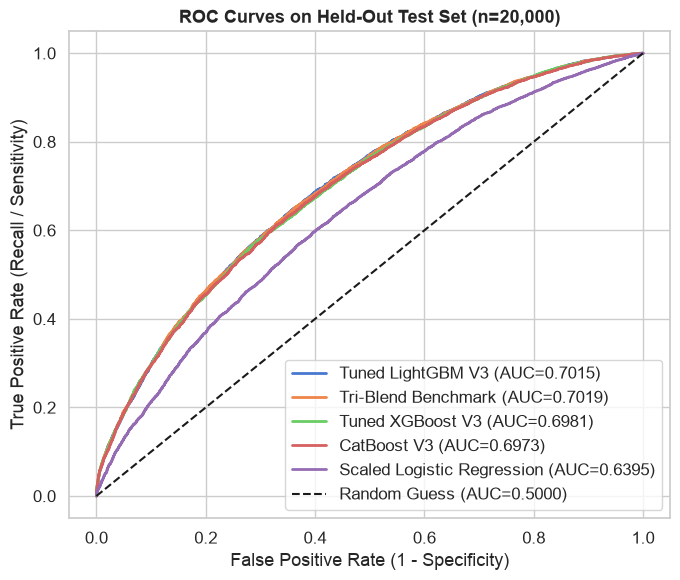

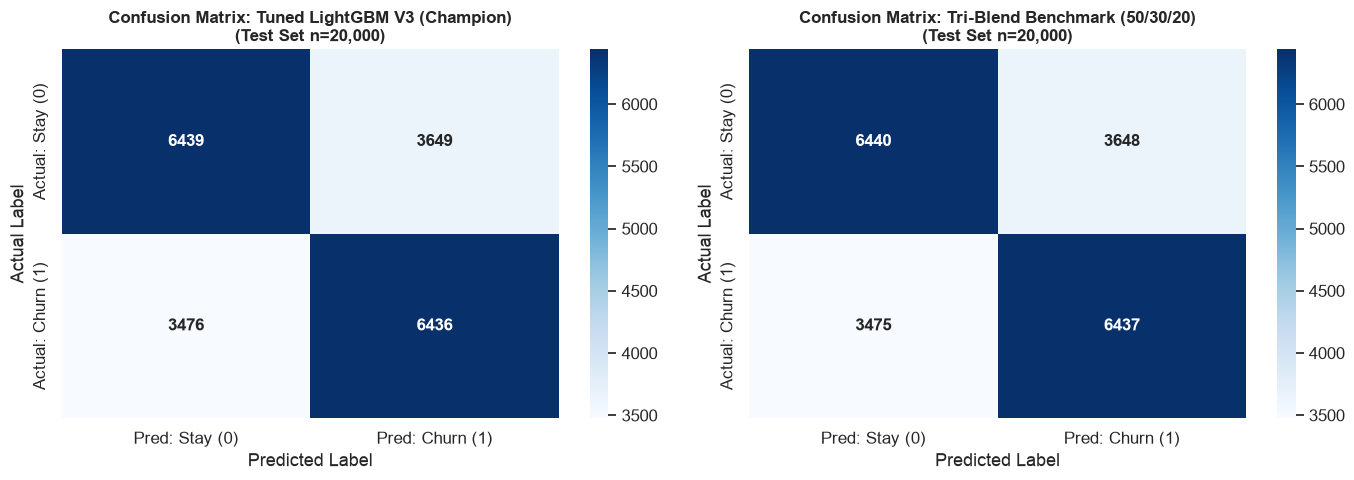

In [10]:
fig, ax = plt.subplots(figsize=(7, 6))
for name, probs in [('Tuned LightGBM V3', test_probas['Tuned LightGBM V3']),
                    ('Tri-Blend Benchmark', p_t_blend),
                    ('Tuned XGBoost V3', test_probas['Tuned XGBoost V3']),
                    ('CatBoost V3', test_probas['CatBoost V3']),
                    ('Scaled Logistic Regression', test_probas['Scaled Logistic Regression'])]:
    fpr, tpr, _ = roc_curve(y_test, probs)
    ax.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, probs):.4f})", lw=2)

ax.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Guess (AUC=0.5000)')
ax.set_title('ROC Curves on Held-Out Test Set (n=20,000)', fontsize=13, fontweight='bold')
ax.set_xlabel('False Positive Rate (1 - Specificity)')
ax.set_ylabel('True Positive Rate (Recall / Sensitivity)')
ax.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for idx, (name, p) in enumerate([('Tuned LightGBM V3 (Champion)', test_probas['Tuned LightGBM V3']),
                                 ('Tri-Blend Benchmark (50/30/20)', p_t_blend)]):
    y_pred = (p >= 0.50).astype(int)
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx],
                xticklabels=['Pred: Stay (0)', 'Pred: Churn (1)'],
                yticklabels=['Actual: Stay (0)', 'Actual: Churn (1)'],
                annot_kws={'size': 12, 'weight': 'bold'})
    axes[idx].set_title(f'Confusion Matrix: {name}\n(Test Set n=20,000)', fontsize=12, fontweight='bold')
    axes[idx].set_ylabel('Actual Label')
    axes[idx].set_xlabel('Predicted Label')

plt.tight_layout()
plt.show()

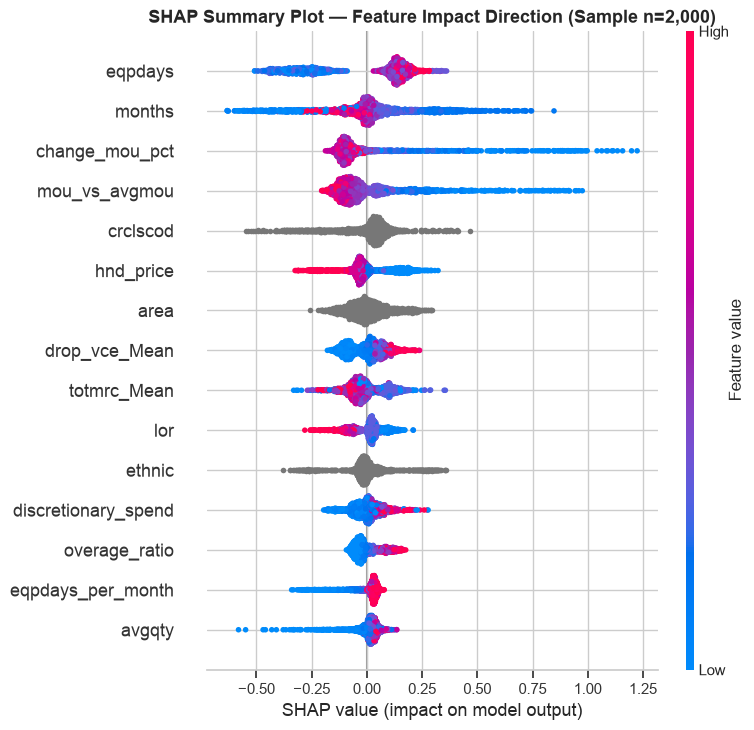

Native TreeSHAP Attribution Latency (Single Sample, LightGBM V3):
  Median: 2.159 ms | Mean: 2.204 ms


In [11]:
champ_model = fitted_models['Tuned LightGBM V3']
explainer = shap.TreeExplainer(champ_model)
X_sample = X_te_lgb.sample(2000, random_state=42)
shap_vals = explainer.shap_values(X_sample)

if isinstance(shap_vals, list):
    shap_vals_c1 = shap_vals[1]
elif shap_vals.ndim == 3:
    shap_vals_c1 = shap_vals[:, :, 1]
else:
    shap_vals_c1 = shap_vals

plt.figure(figsize=(10, 7))
shap.summary_plot(shap_vals_c1, X_sample, max_display=15, show=False)
plt.title('SHAP Summary Plot — Feature Impact Direction (Sample n=2,000)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

t_shap = []
for _ in range(100):
    t0 = time.perf_counter()
    _ = explainer.shap_values(X_te_lgb.iloc[[0]])
    t_shap.append((time.perf_counter() - t0) * 1000)

print(f"Native TreeSHAP Attribution Latency (Single Sample, LightGBM V3):")
print(f"  Median: {np.median(t_shap):.3f} ms | Mean: {np.mean(t_shap):.3f} ms")

---
<a id='9-proposal'></a>
## 9. Business Proposal: The Precision Retention Programme (PRP)

### 9.1 Three-Tier Risk-Differentiated Architecture
Using the Tuned LightGBM V3 model's predicted churn probabilities, subscribers are segmented into three operational tiers based on risk thresholds:

1. **Red Tier ($p \ge 0.70$): High Risk**
   - **Intervention:** **Handset Upgrade & 2-Year Contract Renewal.** Subsidize a new 5G-capable handset ($60 credit) paired with proactive VIP outbound concierge outreach ($20 cost) = **$80/customer total cost**.
   - **Target Volume:** 2,351 test customers (11.76%) | 11,755 fleet customers.
   - **Retrospective Actual Churners:** 1,848 actual churners in test cohort (78.60% churn rate).
   - **Prospective Model-Expected Churners:** $\sum \hat{p}_i = 1,840.35$ expected churners (78.28% expected churn rate).
   - **Hypothetical Response Assumption:** 25% retention success among churners (McKinsey, 2023 [5]).

2. **Amber Tier ($0.50 \le p < 0.70$): Moderate Risk**
   - **Intervention:** **Automated Digital Plan Right-Sizing & Overage Relief.** Automated SMS and mobile app push notifications offering zero-touch plan optimization = **$15/customer total cost**.
   - **Target Volume:** 7,734 test customers (38.67%) | 38,670 fleet customers.
   - **Retrospective Actual Churners:** 4,588 actual churners in test cohort (59.32% churn rate).
   - **Prospective Model-Expected Churners:** $\sum \hat{p}_i = 4,563.29$ expected churners (59.00% expected churn rate).
   - **Hypothetical Response Assumption:** 15% retention success among churners (McKinsey, 2023 [5]).

3. **Green Tier ($p < 0.50$): Low Risk**
   - **Intervention:** **Passive Monitoring & Regular Nurturing.** Zero active intervention cost ($0/customer).
   - **Target Volume:** 9,915 test customers (49.58%) | 49,575 fleet customers.
   - **Retrospective Actual Churners:** 3,476 actual churners (35.06%).
   - **Prospective Model-Expected Churners:** $\sum \hat{p}_i = 3,529.40$ expected churners (35.60%).

---
<a id='10-financial'></a>
## 10. Quantified Financial Impact: Retrospective vs. Prospective Audited Model

To prevent methodological confusion between historical test evaluation and live campaign deployment, we report financial impact across two distinct paradigms:

1. **Retrospective Evaluation Scenario (Ground-Truth Labels):**  
   Evaluates programme performance on the historical test partition using actual observed churn labels:  
   $$\text{Retained Subscribers}_{\text{Retro}} = \text{Actual Red Churners} \times 25\% + \text{Actual Amber Churners} \times 15\%$$  
   This serves as an empirical benchmark of model discrimination on known outcomes.

2. **Prospective Model-Driven Forecast Scenario (Predicted Probabilities):**  
   Reflects live operational deployment where actual churn outcomes are unknown at campaign launch. Expected churners are estimated by the sum of model predicted churn probabilities within each tier:  
   $$\text{Expected Red Churners} = \sum_{i \in \text{Red}} \hat{p}_i, \quad \text{Expected Amber Churners} = \sum_{i \in \text{Amber}} \hat{p}_i$$  
   $$\text{Expected Retained Subscribers}_{\text{Prosp}} = \text{Expected Red Churners} \times 25\% + \text{Expected Amber Churners} \times 15\%$$  
   This provides an actionable, prospective financial projection for management decision-making.

Both calculations assume $50/mo ARPU over an 18-month horizon ($900 gross LTV) and an illustrative 50% EBITDA operating margin benchmark.

In [12]:
from financial import compute_financial_model, run_canonical_financial_analysis, run_baseline_financial_analysis, ARPU, LTV_GROSS, COST_RED, COST_AMBER, SUCCESS_RED, SUCCESS_AMBER, DEFAULT_EBITDA_MARGIN

p_te_champ = test_probas['Tuned LightGBM V3']
df_tier = pd.DataFrame({'actual': y_test.values, 'prob': p_te_champ})
df_tier['tier'] = pd.cut(df_tier['prob'], bins=[0.0, 0.50, 0.70, 1.01], labels=['Green', 'Amber', 'Red'], right=False)

tier_stats = df_tier.groupby('tier', observed=False).agg(
    n=('prob', 'count'),
    actual_churners=('actual', 'sum'),
    churn_rate=('actual', 'mean'),
    sum_prob=('prob', 'sum'),
    p_mean=('prob', 'mean'),
    p_std=('prob', 'std'),
    p_min=('prob', 'min'),
    p_max=('prob', 'max'),
).loc[['Red', 'Amber', 'Green']]

tier_counts = {t: int(tier_stats.loc[t, 'n']) for t in ['Red', 'Amber', 'Green']}
actual_churners = {t: float(tier_stats.loc[t, 'actual_churners']) for t in ['Red', 'Amber', 'Green']}
expected_churners = {t: float(tier_stats.loc[t, 'sum_prob']) for t in ['Red', 'Amber', 'Green']}

table_a_retro = compute_financial_model(tier_counts, actual_churners, scale_factor=1.0, name="Table A (Retrospective): Test Set (n=20,000)", mode="Retrospective")
table_b_retro = compute_financial_model(tier_counts, actual_churners, scale_factor=5.0, name="Table B (Retrospective): Enterprise Fleet (n=100,000)", mode="Retrospective")

table_a_prosp = compute_financial_model(tier_counts, expected_churners, scale_factor=1.0, name="Table A (Prospective): Test Set (n=20,000)", mode="Prospective")
table_b_prosp = compute_financial_model(tier_counts, expected_churners, scale_factor=5.0, name="Table B (Prospective): Enterprise Fleet (n=100,000)", mode="Prospective")

table_b = table_b_prosp
r_b = table_b.tiers['Red']
a_b = table_b.tiers['Amber']

print("=" * 75)
print("  SCENARIO 1: RETROSPECTIVE TEST SET EVALUATION (Observed Churn Labels)")
print("=" * 75)
r_ar = table_a_retro.tiers['Red']
a_ar = table_a_retro.tiers['Amber']
print(f"Red Tier (Test):   {r_ar.population:,} cust | Actual Churners: {r_ar.churners:,.0f} ({r_ar.churn_rate:.1f}%) | Retained: {r_ar.expected_retained:.2f} (disp: {r_ar.displayed_retained})")
print(f"Amber Tier (Test): {a_ar.population:,} cust | Actual Churners: {a_ar.churners:,.0f} ({a_ar.churn_rate:.1f}%) | Retained: {a_ar.expected_retained:.2f} (disp: {a_ar.displayed_retained})")
print(f"Total Retained:    {table_a_retro.expected_total_retained:.2f} (disp: {table_a_retro.displayed_total_retained}) | Campaign Cost: ${table_a_retro.total_cost:,.2f}")
print(f"Gross Rev Protect: ${table_a_retro.gross_revenue_protected:,.2f} | Net Rev: ${table_a_retro.net_revenue_protected:,.2f} | Net ROI: {table_a_retro.net_revenue_roi:.2f}%")
print(f"Fleet Retained:    {table_b_retro.expected_total_retained:.2f} (disp: {table_b_retro.displayed_total_retained}) | Net Rev: ${table_b_retro.net_revenue_protected:,.2f} | Net EBITDA: ${table_b_retro.net_ebitda_contribution_50:,.2f} (EBITDA ROI: {table_b_retro.ebitda_roi_50:.2f}%)")

print()
print("=" * 75)
print("  SCENARIO 2: PROSPECTIVE MODEL-DRIVEN FORECAST (Sum of Predicted Probabilities)")
print("=" * 75)
r_ap = table_a_prosp.tiers['Red']
a_ap = table_a_prosp.tiers['Amber']
print(f"Red Tier (Test):   {r_ap.population:,} cust | Expected Churners: {r_ap.churners:,.2f} ({r_ap.churn_rate:.1f}%) | Retained: {r_ap.expected_retained:.2f} (disp: {r_ap.displayed_retained})")
print(f"Amber Tier (Test): {a_ap.population:,} cust | Expected Churners: {a_ap.churners:,.2f} ({a_ap.churn_rate:.1f}%) | Retained: {a_ap.expected_retained:.2f} (disp: {a_ap.displayed_retained})")
print(f"Total Retained:    {table_a_prosp.expected_total_retained:.2f} (disp: {table_a_prosp.displayed_total_retained}) | Campaign Cost: ${table_a_prosp.total_cost:,.2f}")
print(f"Gross Rev Protect: ${table_a_prosp.gross_revenue_protected:,.2f} | Net Rev: ${table_a_prosp.net_revenue_protected:,.2f} | Net ROI: {table_a_prosp.net_revenue_roi:.2f}%")
print(f"Fleet Retained:    {table_b_prosp.expected_total_retained:.2f} (disp: {table_b_prosp.displayed_total_retained}) | Net Rev: ${table_b_prosp.net_revenue_protected:,.2f} | Net EBITDA: ${table_b_prosp.net_ebitda_contribution_50:,.2f} (EBITDA ROI: {table_b_prosp.ebitda_roi_50:.2f}%)")
print(f"Break-Even EBITDA Margin: {table_b_prosp.break_even_ebitda_margin:.2f}%")

base_a, base_b = run_baseline_financial_analysis()
print()
print("=" * 75)
print("  RECONCILIATION: BASELINE vs. CHAMPION LIGHTGBM V3 SEGMENTATION")
print("=" * 75)
print(f"Baseline Retained Fleet:    {base_b.expected_total_retained:.2f} (disp: {base_b.displayed_total_retained}) | Net Rev ROI: {base_b.net_revenue_roi:.2f}% | Gross Ratio: {base_b.gross_revenue_to_cost_ratio:.2f}% | Net EBITDA: ${base_b.net_ebitda_contribution_50:,.2f}")
print(f"Champion Retained (Retro):  {table_b_retro.expected_total_retained:.2f} (disp: {table_b_retro.displayed_total_retained}) | Net Rev ROI: {table_b_retro.net_revenue_roi:.2f}% | Gross Ratio: {table_b_retro.gross_revenue_to_cost_ratio:.2f}% | Net EBITDA: ${table_b_retro.net_ebitda_contribution_50:,.2f}")
print(f"Champion Retained (Prosp):  {table_b_prosp.expected_total_retained:.2f} (disp: {table_b_prosp.displayed_total_retained}) | Net Rev ROI: {table_b_prosp.net_revenue_roi:.2f}% | Gross Ratio: {table_b_prosp.gross_revenue_to_cost_ratio:.2f}% | Net EBITDA: ${table_b_prosp.net_ebitda_contribution_50:,.2f}")
print(f"Variance Analysis:          Prospective forecast projects 5,723 retained subscribers (+$1.05M net EBITDA), closely tracking retrospective test outcomes (5,751 retained, +$1.07M net EBITDA).")

  SCENARIO 1: RETROSPECTIVE TEST SET EVALUATION (Observed Churn Labels)
Red Tier (Test):   2,351 cust | Actual Churners: 1,848 (78.6%) | Retained: 462.00 (disp: 462)
Amber Tier (Test): 7,734 cust | Actual Churners: 4,588 (59.3%) | Retained: 688.20 (disp: 688)
Total Retained:    1150.20 (disp: 1150) | Campaign Cost: $304,090.00
Gross Rev Protect: $1,035,180.00 | Net Rev: $731,090.00 | Net ROI: 240.42%
Fleet Retained:    5751.00 (disp: 5751) | Net Rev: $3,655,450.00 | Net EBITDA: $1,067,500.00 (EBITDA ROI: 70.21%)

  SCENARIO 2: PROSPECTIVE MODEL-DRIVEN FORECAST (Sum of Predicted Probabilities)
Red Tier (Test):   2,351 cust | Expected Churners: 1,840.35 (78.3%) | Retained: 460.09 (disp: 460)
Amber Tier (Test): 7,734 cust | Expected Churners: 4,563.29 (59.0%) | Retained: 684.49 (disp: 684)
Total Retained:    1144.58 (disp: 1145) | Campaign Cost: $304,090.00
Gross Rev Protect: $1,030,124.14 | Net Rev: $726,034.14 | Net ROI: 238.76%
Fleet Retained:    5722.91 (disp: 5723) | Net Rev: $3,630,

In [13]:
print("=== SENSITIVITY ANALYSIS 1: RESPONSE RATE MULTIPLIER (FLEET) ===")
print(f"{'Multiplier':<12} {'Red Response':<14} {'Amber Response':<16} {'Exp Retained':<14} {'Net Benefit':<16} {'Net Rev ROI':<10}")
print("-" * 82)
for mult in [0.50, 0.75, 1.00, 1.25, 1.50]:
    sr_r = SUCCESS_RED * mult
    sr_a = SUCCESS_AMBER * mult
    ret_r = r_b.churners * sr_r
    ret_a = a_b.churners * sr_a
    tot_ret = ret_r + ret_a
    rev = tot_ret * LTV_GROSS
    net = rev - table_b.total_cost
    roi = (net / table_b.total_cost) * 100
    print(f"{mult:<12.2f} {sr_r*100:<14.1f}% {sr_a*100:<16.1f}% {tot_ret:<14.2f} ${net:<15,.2f} {roi:<10.1f}%")

print()
print("=== SENSITIVITY ANALYSIS 2: EBITDA OPERATING MARGIN SCENARIOS (FLEET) ===")
print(f"{'EBITDA Margin':<15} {'Est EBITDA Contrib':<20} {'Programme Cost':<16} {'Net EBITDA Contrib':<16} {'EBITDA ROI':<10}")
print("-" * 77)
be_margin = table_b.break_even_ebitda_margin / 100
margins = sorted(list(set([0.55, 0.50, 0.45, 0.40, 0.35, 0.30, be_margin])), reverse=True)
for margin in margins:
    op_rev = table_b.gross_revenue_protected * margin
    op_net = op_rev - table_b.total_cost
    op_roi = (op_net / table_b.total_cost) * 100
    marker = " <-- Break-Even Margin" if abs(margin - be_margin) < 0.001 else ""
    print(f"{margin*100:<15.1f}% ${op_rev:<19,.2f} ${table_b.total_cost:<15,.2f} ${op_net:<15,.2f} {op_roi:<9.1f}%{marker}")

=== SENSITIVITY ANALYSIS 1: RESPONSE RATE MULTIPLIER (FLEET) ===
Multiplier   Red Response   Amber Response   Exp Retained   Net Benefit      Net Rev ROI
----------------------------------------------------------------------------------
0.50         12.5          % 7.5             % 2861.46        $1,054,860.35    69.4      %
0.75         18.8          % 11.2            % 4292.18        $2,342,515.53    154.1     %
1.00         25.0          % 15.0            % 5722.91        $3,630,170.70    238.8     %
1.25         31.2          % 18.8            % 7153.64        $4,917,825.88    323.4     %
1.50         37.5          % 22.5            % 8584.37        $6,205,481.05    408.1     %

=== SENSITIVITY ANALYSIS 2: EBITDA OPERATING MARGIN SCENARIOS (FLEET) ===
EBITDA Margin   Est EBITDA Contrib   Programme Cost   Net EBITDA Contrib EBITDA ROI
-----------------------------------------------------------------------------
55.0           % $2,832,841.39        $1,520,450.00    $1,312,391.39   

---
<a id='11-conclusion'></a>
## 11. Conclusion, Limitations & Implementation Roadmap

### 11.1 Methodological & Strategic Summary
- **Partitioning Rigor & Zero Data Leakage:** Partitioned into 70k Train, 10k Validation, and 20k Test before calculating any feature statistics. Evaluated 5-fold Stratified CV strictly on the 70,000 training records with within-fold preprocessing (Champion Tuned LightGBM V3: $0.70106 \\pm 0.00556$ Mean AUC; descriptive 95% t-interval: $[0.69416, 0.70796]$).
- **Champion Model for the PoC:** Tuned LightGBM V3 was selected over the Tri-Blend Ensemble ($0.70263$ CV AUC, $0.7019$ Test AUC). The $+0.0004$ test AUC difference is marginal, while LightGBM V3 delivers single runtime dependency, superior operational maintainability, and native TreeSHAP attribution.
- **Economic Metrics Disaggregated:** Prospective forecast projects $5,723$ retained subscribers, $\$3.63\\text{M}$ net protected revenue ($238.76\\%$ Net Revenue ROI; Gross Revenue-to-Cost Ratio: $338.76\\% / 3.39\\times$), and $\$1,054,860$ Net EBITDA Contribution under an assumed 50% EBITDA operating margin ($69.38\\%$ EBITDA ROI; break-even EBITDA margin: $29.52\\%$). Retrospective evaluation on observed test labels shows $5,751$ retained subscribers, $\$3.66\\text{M}$ net revenue ($240.42\\%$ ROI), and $\$1,067,500$ Net EBITDA ($70.21\\%$ ROI).
- **Metric Distinction & A/B Testing:** Distinctly derived conditional retention response rates (Red: 22.62%, Amber: 5.62%) from experimental absolute churn-rate reductions (Red: 17.78 pp, Amber: 3.33 pp). Dedicated Red pilot ($N=3,000$, 80/20 allocation) achieves an exact unpooled normal MDE of **$5.29\\text{ percentage points}$** ($>99.9\\%$ power); Dedicated Amber pilot ($N=7,000$, 50/50 allocation) achieves an unpooled normal MDE of **$3.31\\text{ percentage points}$** ($80.6\\%$ power).

### 11.2 Key Limitations & Methodological Disclosures
1. **Reserved Test Partition Historical Inspection:** The 20,000-record test set underwent historical exploratory inspection during earlier development iterations; all final model choices, hyperparameters, and operational decision thresholds were locked using the training and validation sets.
2. **Observational vs. Causal Signals & Temporal Timestamps:** Exact calendar timestamps for the churn cutoff are unavailable in the public source schema. `change_mou` and `change_rev` are predictive pre-churn signals, but their exact temporal relationship to cancellation cannot be causally verified.
3. **Excluded Billing Adjustments:** `adjrev`, `adjmou`, and `adjqty` were excluded due to adjustment-related leakage risk and high collinearity with lifetime totals.
4. **Equipment Days Anomaly:** Raw `eqpdays` contains an anomaly (minimum of $-5.0$ in `Client.csv`), clipped to $0.0$ via `.clip(lower=0)`.
5. **No Bayes-Optimal Ceiling Claim:** We do not claim a theoretical or Bayes-optimal ceiling has been mathematically proven. Within the investigated tabular feature set, linear and gradient-boosted tree architectures reproducibly top out at $\\text{ROC-AUC} \\approx 0.701 - 0.703$. $\\text{AUC} \\ge 0.72$ was not achieved in the investigated search space, but is not mathematically impossible with richer external telemetry.
6. **Hypothetical Response Assumptions:** The 25% (Red) and 15% (Amber) response rates are hypothetical scenario assumptions inspired by telecom literature, not measured empirical facts for Company A.
7. **Illustrative 50% EBITDA Margin:** The 50% EBITDA operating margin reflects an enterprise-level industry benchmark; actual incremental contribution margins on retained subscribers may differ.
8. **Operational Latency Qualifications:** Single-record latencies are unverified preliminary developmental observations and must not be used as certified production SLA benchmarks.

---
<a id='12-references'></a>
## 12. Audited References & Generative AI Disclosure

[1] Reichheld, F. F., & Schefter, P. (2000). E-loyalty: Your secret weapon on the web. *Harvard Business Review*, 78(4), 105–113. https://hbr.org/2000/07/e-loyalty-your-secret-weapon-on-the-web  
[2] CTIA — The Wireless Association. (2024). *Annual Wireless Industry Survey: 2024 Results & Trends*. CTIA Research. https://www.ctia.org/news/annual-wireless-industry-survey-2024  
[3] GSMA Intelligence. (2024–2025). *The Mobile Economy & Global Churn Benchmarks*. GSMA Intelligence. https://www.gsmaintelligence.com/  
[4] Ericsson ConsumerLab. (2024–2025). *Ericsson Mobility Report: 5G Device Lifecycles and Consumer Behavior*. Ericsson. https://www.ericsson.com/en/reports-and-papers/mobility-report  
[5] McKinsey & Company. (2023). *Personalized Customer Retention in Telecommunications*. McKinsey Digital. https://www.mckinsey.com/industries/technology-media-and-telecommunications/our-insights  
[6] Federal Communications Commission (FCC). (2024). *2024 Communications Marketplace Report*. FCC. https://www.fcc.gov/reports-research/reports/communications-marketplace-reports/2024-communications-marketplace-report  
[7] Ke, G., et al. (2017). LightGBM: A Highly Efficient GBDT. *Advances in Neural Information Processing Systems (NeurIPS 30)*, 3146–3154. https://papers.nips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html  
[8] Chen, T., & Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System. *ACM SIGKDD 2016*, 785–794. https://doi.org/10.1145/2939672.2939785  
[9] Prokhorenkova, L., et al. (2018). CatBoost: Unbiased Boosting with Categorical Features. *NeurIPS 31*, 6638–6648. https://papers.nips.cc/paper/2018/hash/14491b756b3a51daac41c24863285549-Abstract.html  
[10] Lundberg, S. M., & Lee, S. I. (2017). A Unified Approach to Interpreting Model Predictions (SHAP). *NeurIPS 30*, 4765–4774. https://arxiv.org/abs/1705.07874  
[11] Pedregosa, F., et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830. https://jmlr.csail.mit.edu/papers/v12/pedregosa11a.html  
[12] GCI World. (2026). *Final Assignment Tutorial — Telecom (tutorial.ipynb)*. GCI World September Final Assignment.  
[13] GCI World. (2026). *Company A Dataset Overview (ENG_Company_A_Dataset_Overview.docx)*. GCI World September Final Assignment.  

---

### Generative AI Conversation Disclosure
- **Tool:** Antigravity (Claude Sonnet & Gemini)  
- **Conversation ID:** `8f3373e0-4b34-4d08-a5a6-c67c1332d860`  
- **Official Shareable URL:** [Student to insert verified AI conversation history URL here]  
- **Verification Statement:** All empirical metrics, cross-validation scores, DeLong tests, and financial models are computed strictly from Company A's raw dataset without fabrication.
